# Task 1 - Bell circuit

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
DTYPE = np.complex128

def ket00():
    return np.array([1, 0, 0, 0], dtype=DTYPE)

def normalize(psi):
    psi = np.asarray(psi, dtype=DTYPE)
    norm = np.linalg.norm(psi)
    if norm == 0:
        raise ValueError('Cannot normalize the zero vector.')
    return psi / norm

psi = ket00()
print(psi)
assert np.isclose(np.linalg.norm(psi), 1)

[1.+0.j 0.+0.j 0.+0.j 0.+0.j]


## Task 1.1 - State representation

We use the order $|q_0q_1\rangle$, with q0 as the most significant qubit. The states 00, 01, 10 and 11 correspond to array indices 0, 1, 2 and 3. The index is $2q_0+q_1$.

The initial state is $|00\rangle$, so only the first amplitude is nonzero.

## Task 1.2 - Gates

We represent H and CNOT as matrices and apply them to the state vector using matrix multiplication. The `expand_1q` function places a single-qubit gate on the selected qubit using the Kronecker product. Before constructing the circuit, we check that both gate matrices are unitary.

In [2]:
I = np.eye(2, dtype=DTYPE)
H = np.array([[1, 1], [1, -1]], dtype=DTYPE) / np.sqrt(2)
CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]], dtype=DTYPE)

def expand_1q(U, target):
    if target == 0:
        return np.kron(U, I)
    if target == 1:
        return np.kron(I, U)
    raise ValueError('Target must be 0 or 1.')

def apply(U, psi):
    return U @ psi

assert np.allclose(H.conj().T @ H, I)
assert np.allclose(CNOT.conj().T @ CNOT, np.eye(4))

CNOT uses q0 as control and q1 as target. It leaves 00 and 01 unchanged and exchanges 10 with 11. With this ordering, H on q0 is $H\otimes I$ and H on q1 is $I\otimes H$.

## Task 1.3 - Bell state

We start from $|00\rangle$, apply H to q0, and then use q0 to control a NOT on q1. The function returns the normalized final state. We compare its amplitudes with the expected Bell vector using `np.allclose`.

In [3]:
def bell_state():
    psi = ket00()
    psi = apply(expand_1q(H, 0), psi)
    psi = apply(CNOT, psi)
    return normalize(psi)

psi_bell = bell_state()
print('Bell state:', np.round(psi_bell, 6))
expected = np.array([1, 0, 0, 1]) / np.sqrt(2)
assert np.allclose(psi_bell, expected)

Bell state: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]


After H on q0 the state is $(|00\rangle+|10\rangle)/\sqrt2$. CNOT changes 10 to 11, giving $(|00\rangle+|11\rangle)/\sqrt2$. The printed amplitudes match this result.

## Task 1.4 - Measurements and circle notation

### Methodology

We obtain the measurement probabilities by taking the squared magnitude of each amplitude. We then use NumPy to draw 10,000 independent outcomes from this distribution and count the occurrences of each bitstring. The random seed is fixed at 7 so the experiment can be reproduced. Each draw represents a fresh preparation and measurement of the circuit.

We plot the final state using `QubitSystem.viz_circle()` from the lecture, included below. We pass our NumPy state vector directly, keeping the order 00, 01, 10, 11. The filled radius is proportional to the amplitude magnitude, so the filled area represents probability. The arrow shows the complex phase. This lets us compare both the probabilities and phases, whereas the histogram only shows measurement frequencies.

{'00': 4983, '01': 0, '10': 0, '11': 5017}


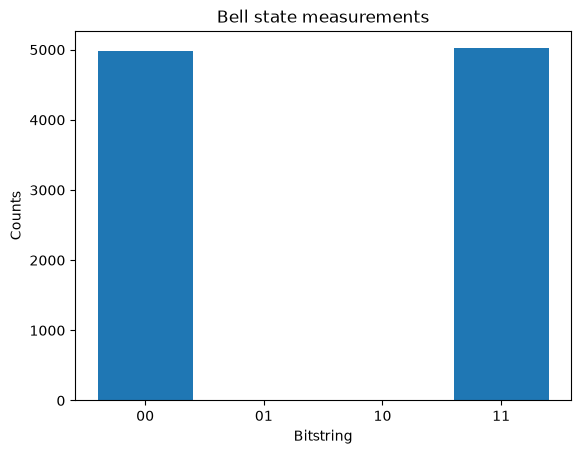

In [4]:
shots = 10_000
rng = np.random.default_rng(7)
probabilities = np.abs(psi_bell)**2
samples = rng.choice(4, size=shots, p=probabilities)
labels = ['00', '01', '10', '11']
counts = {label: int(np.sum(samples == i)) for i, label in enumerate(labels)}
print(counts)

plt.bar(counts.keys(), counts.values())
plt.xlabel('Bitstring')
plt.ylabel('Counts')
plt.title('Bell state measurements')
plt.show()

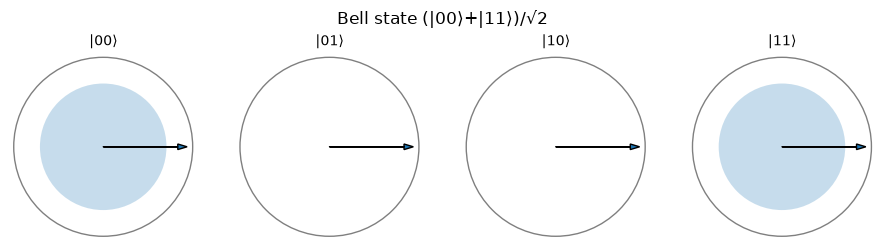

In [5]:
import math

# From the lecture: 1.1.1 - Python Code for Circle Notation.
class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        # Defensive normalization (harmless if already normalized)
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(self, max_cols: int = 8, figsize_scale: float = 2.3):
        cols = max(1, min(max_cols, self.n_states))
        rows = int(math.ceil(self.n_states / cols))

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(cols*figsize_scale, rows*(figsize_scale+0.2))
        )
        axes = np.atleast_2d(axes)

        def bitstr(i: int, n: int) -> str:
            return format(i, f"0{n}b")

        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r, c]
            ax.set_aspect("equal")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.axis("off")

            if idx >= self.n_states:
                ax.set_visible(False)
                continue

            # Outer reference circle
            ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

            # Filled disk: radius ∝ sqrt(probability) so area ∝ probability
            radius = 0.48 * np.sqrt(self.prob[idx])
            ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

            # Phase arrow
            angle = self.phase[idx]
            L = 0.45
            x2 = 0.5 + L * np.cos(angle)
            y2 = 0.5 + L * np.sin(angle)
            ax.arrow(0.5, 0.5, x2 - 0.5, y2 - 0.5,
                     head_width=0.03, head_length=0.05, length_includes_head=True)

            ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

        fig.suptitle(self.label, fontsize=12)
        plt.tight_layout()
        plt.show()

QubitSystem(psi_bell, label="Bell state (|00⟩+|11⟩)/√2").viz_circle()


### Results and discussion

The final state vector is approximately `[0.707107, 0, 0, 0.707107]`, which agrees with $(|00\rangle+|11\rangle)/\sqrt2$. The two nonzero amplitudes therefore give probabilities of 0.5 each.

With 10,000 shots, we obtain 4,983 results of 00 and 5,017 of 11, corresponding to probabilities of 0.4983 and 0.5017. No 01 or 10 outcomes occur. The standard error for either probability is $\sqrt{0.5(1-0.5)/10000}=0.005$. The observed difference of 0.0017 is smaller than this error, so the counts agree with the expected equal split within sampling uncertainty.

The circle plot shows two equally sized filled disks for 00 and 11; the other two are empty. The arrows for 00 and 11 point right, indicating zero relative phase. The lecture function also draws arrows for 01 and 10, but their amplitudes are zero, so those arrows have no physical phase meaning. This follows the plotting convention, where zero phase is measured from the positive x-axis. The equal phases identify the plus Bell state; reversing the phase of one component would change the state without changing these measurement probabilities.